# Tugas Praktikum
Jobsheet 5 - Klasterisasi Hierarki

Pada tugas ini kita akan melakukan clustering HDBSCAN pada dataset nyata dari `sklearn.datasets`, yaitu **digits dataset** (citra angka tulisan tangan 8x8 piksel: 1797 sampel, 64 fitur, 10 kelas).

> Catatan: untuk data citra, fitur piksel mentah (0-16) justru lebih informatif untuk clustering berbasis kepadatan dibandingkan fitur yang di-standarisasi. Kita bandingkan keduanya di bagian akhir.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import hdbscan
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

### 1. Memuat Dataset Nyata (Digits)

In [2]:
digits = load_digits()
X = digits.data.astype(float)
y_true = digits.target

print("Shape data:", X.shape)
print("Jumlah kelas asli:", len(np.unique(y_true)))

Shape data: (1797, 64)
Jumlah kelas asli: 10


### 2. Clustering dengan HDBSCAN

In [3]:
hdb = hdbscan.HDBSCAN(min_cluster_size=15, min_samples=5)
labels = hdb.fit_predict(X)

### 3. Laporan Hasil: Jumlah Cluster dan Noise

In [4]:
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)

print(f"Jumlah cluster terbentuk : {n_clusters}")
print(f"Jumlah titik noise        : {n_noise} ({n_noise / len(labels) * 100:.1f}%)")
print(f"Adjusted Rand Index (vs label asli): {adjusted_rand_score(y_true, labels):.3f}")

mask = labels != -1
print(f"Silhouette Score (tanpa noise): {silhouette_score(X[mask], labels[mask]):.3f}")
print(f"Davies-Bouldin Index (tanpa noise): {davies_bouldin_score(X[mask], labels[mask]):.3f}")

Jumlah cluster terbentuk : 13
Jumlah titik noise        : 621 (34.6%)
Adjusted Rand Index (vs label asli): 0.408
Silhouette Score (tanpa noise): 0.253
Davies-Bouldin Index (tanpa noise): 1.403


### 4. Visualisasi dengan Reduksi Dimensi (PCA)
Karena data berdimensi 64, kita reduksi ke 2D menggunakan PCA untuk visualisasi.

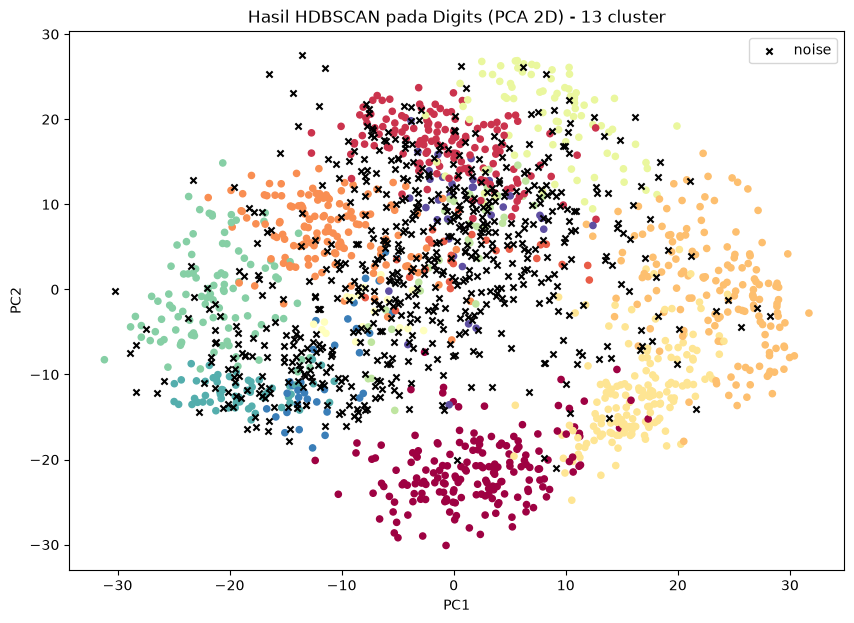

In [5]:
X_pca = PCA(n_components=2, random_state=42).fit_transform(X)
noise = labels == -1

plt.figure(figsize=(10, 7))
plt.scatter(X_pca[~noise, 0], X_pca[~noise, 1], c=labels[~noise], cmap='Spectral', s=20)
plt.scatter(X_pca[noise, 0], X_pca[noise, 1], c='black', marker='x', s=20, label='noise')
plt.title(f'Hasil HDBSCAN pada Digits (PCA 2D) - {n_clusters} cluster')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()
plt.show()

Sebagai pembanding, berikut visualisasi label asli dataset:

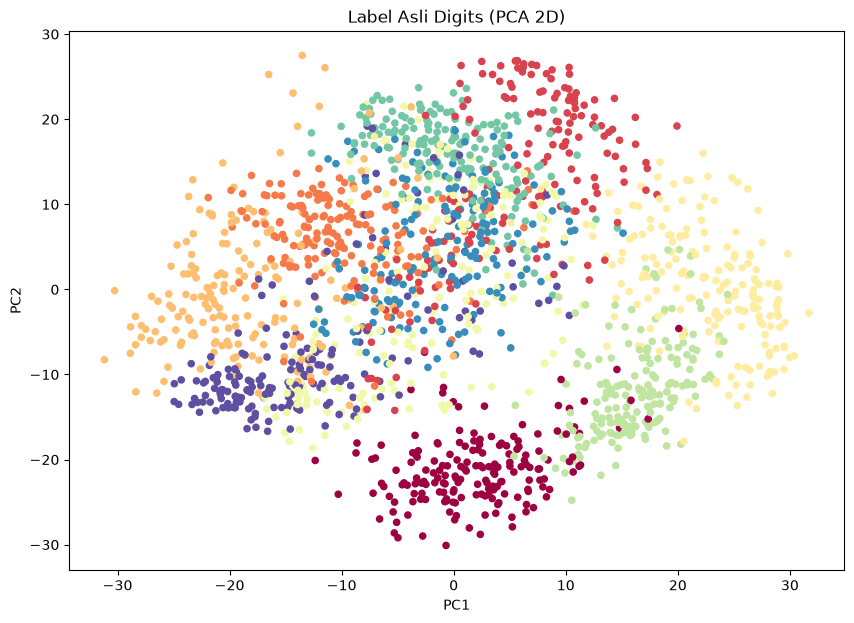

In [6]:
plt.figure(figsize=(10, 7))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_true, cmap='Spectral', s=20)
plt.title('Label Asli Digits (PCA 2D)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

### 5. Visualisasi dengan t-SNE

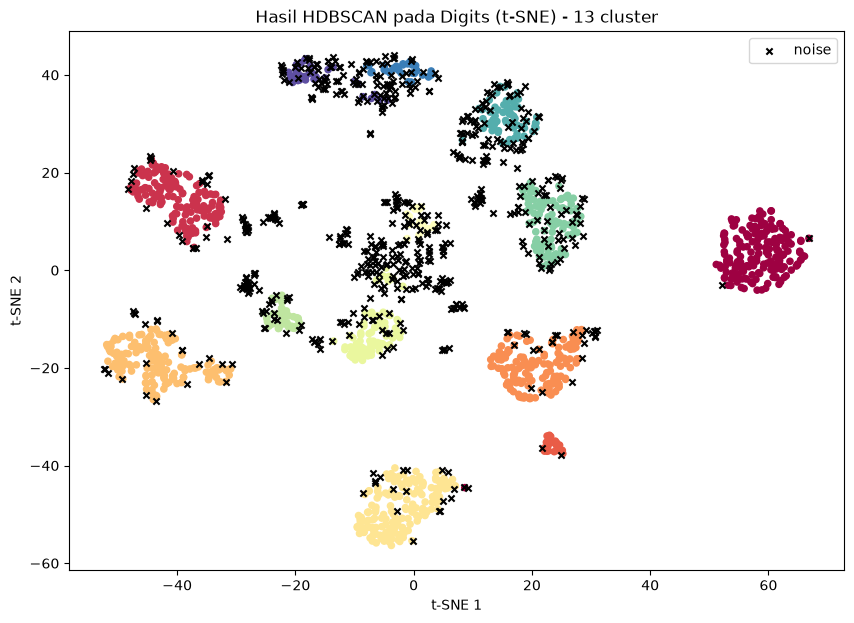

In [7]:
X_tsne = TSNE(n_components=2, init='random', random_state=42, perplexity=30).fit_transform(X)

plt.figure(figsize=(10, 7))
plt.scatter(X_tsne[~noise, 0], X_tsne[~noise, 1], c=labels[~noise], cmap='Spectral', s=20)
plt.scatter(X_tsne[noise, 0], X_tsne[noise, 1], c='black', marker='x', s=20, label='noise')
plt.title(f'Hasil HDBSCAN pada Digits (t-SNE) - {n_clusters} cluster')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.legend()
plt.show()

### 6. Tabulasi Silang: Cluster HDBSCAN vs Digit Asli

In [8]:
ct = pd.crosstab(pd.Series(labels, name='cluster'), pd.Series(y_true, name='digit'))
ct

digit,0,1,2,3,4,5,6,7,8,9
cluster,,,,,,,,,,
-1,2,44,36,82,25,114,19,35,148,116
0,176,0,0,0,0,0,1,0,0,0
1,0,0,0,0,0,0,0,144,0,0
2,0,25,0,0,0,0,0,0,0,0
3,0,0,141,0,0,0,0,0,0,0
4,0,0,0,0,156,0,0,0,0,0
5,0,0,0,0,0,0,161,0,0,0
6,0,0,0,0,0,0,0,0,18,0
7,0,75,0,0,0,0,0,0,8,0


### 7. Pengaruh Pra-pengolahan terhadap Hasil

In [9]:
rows = []
for nama, data in [('fitur mentah', X), ('standarisasi', StandardScaler().fit_transform(X))]:
    lbl = hdbscan.HDBSCAN(min_cluster_size=15, min_samples=5).fit_predict(data)
    nc = len(set(lbl)) - (1 if -1 in lbl else 0)
    nn = list(lbl).count(-1)
    rows.append({
        'pra-pengolahan': nama,
        'n_cluster': nc,
        'n_noise': nn,
        'noise_%': round(nn / len(lbl) * 100, 1),
        'ARI': round(adjusted_rand_score(y_true, lbl), 3),
    })
pd.DataFrame(rows)

,pra-pengolahan,n_cluster,n_noise,noise_%,ARI
0,fitur mentah,13,621,34.6,0.408
1,standarisasi,9,927,51.6,0.198


### 8. Analisis Singkat
Apakah hasil clustering HDBSCAN sesuai dengan label asli dataset?

**Ringkasan hasil:**

* **Jumlah cluster:** HDBSCAN membentuk **13 klaster** dari 10 kelas asli.
* **Noise:** sekitar **34.6%** sampel (621 titik) ditandai sebagai noise (`-1`).
* **Adjusted Rand Index (ARI):** ~**0.41** (kesesuaian moderat dengan label asli).

**Apakah sesuai dengan label asli?**

Hasilnya **sebagian sesuai**:

1. **Klaster sangat murni.** Dari tabulasi silang, hampir setiap klaster didominasi oleh satu digit tunggal. Contoh: klaster `0` → hampir seluruhnya angka 0, klaster `4` → angka 4, klaster `5` → angka 6, klaster `10` → angka 9. Artinya HDBSCAN berhasil menemukan kelompok yang bermakna secara visual.
2. **Beberapa digit terpecah.** Digit yang tulisan tangannya bervariasi (terutama **1** dan **5**) terbagi ke beberapa klaster, sehingga jumlah klaster (13) melebihi jumlah kelas (10).
3. **Noise terkonsentrasi pada digit ambigu.** Titik noise banyak berasal dari digit **8, 9, 5, 3, 1** — kelas yang memang sering saling tumpang tindih secara visual.
4. **ARI moderat (0.41).** Nilai ini menunjukkan klaster HDBSCAN **tidak identik** dengan label asli, namun jauh lebih baik dari penempatan acak. Hal ini wajar karena HDBSCAN bekerja **tanpa label** dan mengelompokkan berdasarkan **kepadatan** di ruang fitur, bukan berdasarkan kelas.
5. **Pra-pengolahan berpengaruh.** Menggunakan **fitur piksel mentah** memberikan hasil yang lebih baik (ARI lebih tinggi, noise lebih sedikit) dibandingkan **standarisasi**. Untuk data citra, standarisasi per-piksel justru menghilangkan informasi kepadatan yang penting.

**Kesimpulan:** Clustering HDBSCAN pada digits **sesuai secara parsial** dengan label asli. Algoritma ini mampu memisahkan sebagian besar digit menjadi klaster yang murni, tetapi karena berbasis kepadatan dan tidak diberi tahu jumlah kelas, hasilnya tidak persis sama dengan 10 kelas asli. Ini memperlihatkan kekuatan HDBSCAN dalam menemukan struktur tersembunyi sekaligus keterbatasannya untuk mereproduksi label kelas secara tepat.